# Лабораторная работа № 7. Мультимодальный датасет

Вариант 6

Аудиокаталог русской речи. Задача — распознавать вопросы и находить похожие записи с ограничением по длительности.

## 1. Загрузка и подготовка

Берём Common Voice Corpus 17.0 (`ru`) из публичного зеркала с фиксированной ревизией. Используем `dev` и `test` как источник кандидатов. Из них выбираем по 500 вопросов и прочих фраз. Медиа — MP3, ключ — `clip_key`, полученный из имени файла. Метка вопроса берётся из конечного знака транскрипта. Табличные признаки строятся из слов без пунктуации.

In [1]:
import pandas as pd
from IPython.display import Image, display
from common_voice import FEATURES, ROOT, WORK, prepare
from clap_audio import DIM, embeddings
from assessment import SEEDS, compare, join, quality, retrieval, split
from run import save_result

OUTPUT = WORK / 'notebook'
data, audit = prepare(limit=1000)
display(pd.DataFrame([audit]).T.rename(columns={0: 'Значение'}))
display(data[FEATURES + ['target']].head(3))

,Значение
source_rows,"{'dev': 10203, 'test': 10203}"
unique_candidates,20358
class_candidates,"{0: 19270, 1: 1088}"
selected_rows,1000
speakers,706
missing_age,498
missing_gender,501


,word_count,letter_count,mean_word_length,unique_word_share,target
0,4,25,6.250000,1.0,1
1,4,14,3.500000,1.0,1
2,3,13,4.333333,1.0,1


**Вывод.** Ограничение на число записей от одного диктора и удаление повторов фраз уменьшают влияние частых дикторов и текстов. Аудио подаётся в один и тот же transform при построении индекса и поисковом запросе. Полный препроцессинг двух шардов (20 406 записей) занял 370,71 с на четырёх процессах. [Замер](results/source_preprocess.json) воспроизводится командой `python benchmark_preprocess.py`.

## 2. CLAP-эмбеддинги и проверка качества

MP3 декодируется в моно, ресемплируется до 48 кГц и приводится к окну в 10 секунд. Короткий сигнал повторяется и дополняется нулями по конфигурации `repeatpad`. Штатный препроцессор CLAP рассчитывает 64 log-mel полосы. Замороженный CLAP HTSAT кодирует батчи на CPU через ONNX Runtime. Векторы L2-нормируются и кэшируются в Parquet.

,Значение
rows,1000
dimensions,512
batch_size,8
threads,4
preprocess_s,48.195454
encode_s,126.780743
sample_rows,64
sample_preprocess_s,3.269234
norm_max_error,0.0
cache_hit,True


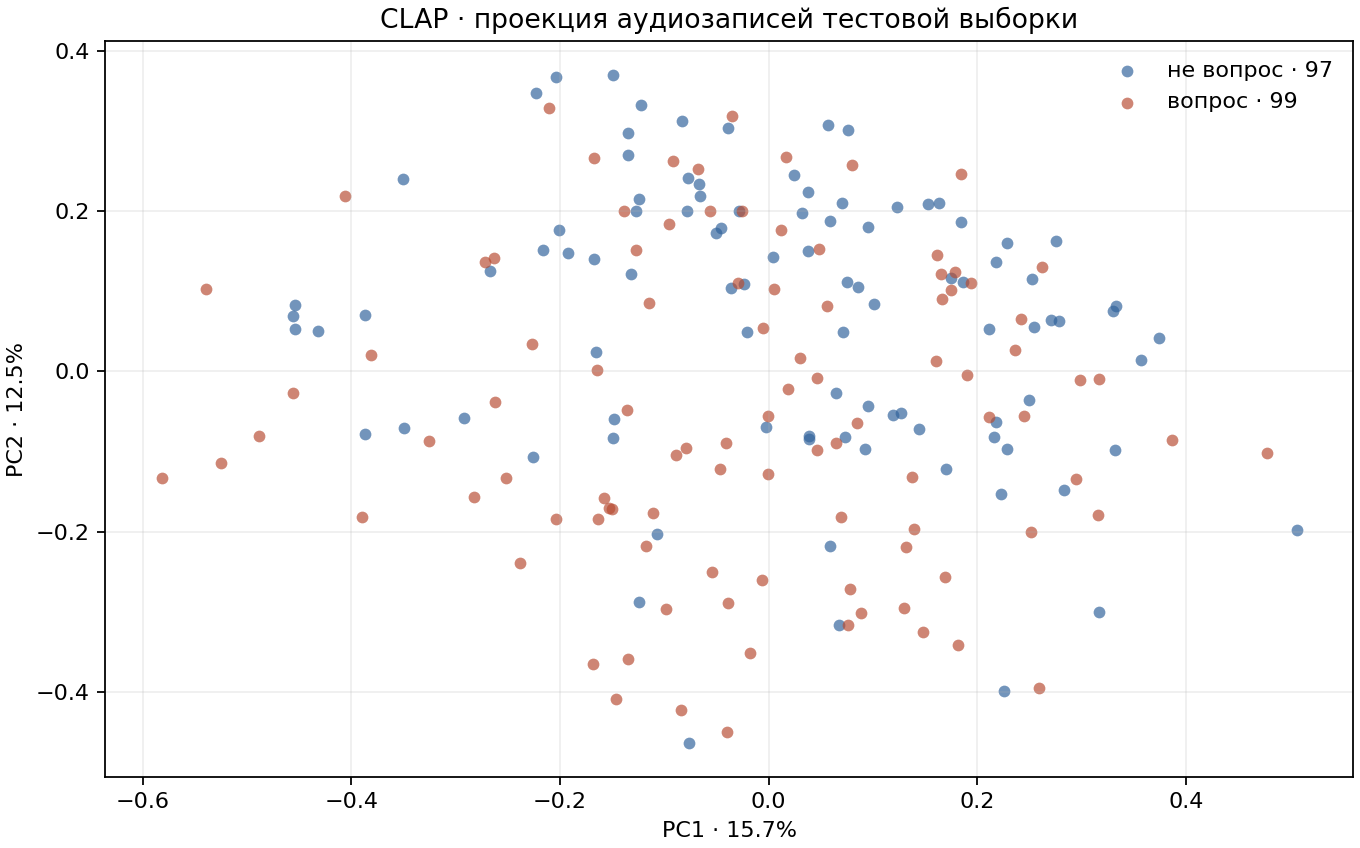

,query,label,neighbors
0,1437af743c,не вопрос,"[{'label': 'не вопрос', 'cosine': 0.9095682501..."
1,a047cde50f,вопрос,"[{'label': 'вопрос', 'cosine': 0.9214906692504..."


,expected,precision_at_5,top_labels
0,не вопрос,1.0,"[не вопрос, не вопрос, не вопрос, не вопрос, н..."
1,вопрос,0.4,"[не вопрос, не вопрос, вопрос, не вопрос, вопрос]"


Точные аудиососеди · precision@5 = 0.630


In [2]:
encoded, stats = embeddings(data, batch_size=8, threads=4, progress=True)
display(pd.DataFrame([stats]).T.rename(columns={0: 'Значение'}))
assert len(encoded) == len(data) and len(encoded.loc[0, 'vector']) == DIM

# Для PCA и соседей используем train-галерею и независимые test-запросы.
frame, vectors = join(data, encoded)
train, test = split(frame, SEEDS[0])
diagnostics = quality(frame, vectors, train, test, OUTPUT / 'pca.png')
display(Image(filename=str(OUTPUT / 'pca.png')))
display(pd.DataFrame(diagnostics['examples']))
display(pd.DataFrame(diagnostics['text_queries'])[['expected', 'precision_at_5', 'top_labels']])
print(f"Точные аудиососеди · precision@5 = {diagnostics['neighbor_precision_at_5']:.3f}")

**Вывод.** Классы на PCA перекрываются. Точные аудиососеди дали precision@5 = 0,630. Текстовый запрос об утверждении нашёл 5 из 5 записей ожидаемого класса, а о вопросе — 2 из 5.

## 3. Соединение и защита от утечки

Проверяем равенство множеств ключей и соединение один к одному. Дикторы разделены между train и test, повторяющихся нормализованных фраз нет. Транскрипт, знак вопроса, идентификаторы, пол, возраст и длительность исключены из матрицы признаков. PCA обучается только на train. Замороженный энкодер не подгоняется по корпусу.

In [3]:
assert len(frame) == len(data) == len(encoded)
assert len(set(frame.iloc[train]['client_id']) & set(frame.iloc[test]['client_id'])) == 0
assert len(set(frame.iloc[train]['phrase']) & set(frame.iloc[test]['phrase'])) == 0
print(f'Join: {len(frame)} строк. Train: {len(train)}. Test: {len(test)}.')
print(f'Признаков: таблица {len(FEATURES)}, аудио {DIM}, вместе {len(FEATURES)+DIM}.')

Join: 1000 строк. Train: 804. Test: 196.
Признаков: таблица 4, аудио 512, вместе 516.


**Вывод.** Ключи сохранились. Модели оцениваются на голосах и фразах, отсутствующих при обучении.

## 4. Сравнение трёх конфигураций

LightGBM обучается с одинаковыми настройками на каждом из двух разбиений. В одном разбиении все конфигурации видят одинаковые строки. Дополнительно сравниваем короткие и длинные фразы, граница определяется медианой числа слов в train.

In [4]:
trials = compare(frame, vectors)
models = [{'seed': row['seed'], 'конфигурация': model, **scores}
          for row in trials for model, scores in row['models'].items()]
display(pd.DataFrame(models).round(4))
display(pd.DataFrame(trials)[['seed', 'train', 'test', 'gain_over_best_single']].round(4))
segments = [{'seed': row['seed'], 'конфигурация': model, 'срез': segment, **scores}
            for row in trials for model, groups in row['segments'].items() for segment, scores in groups.items()]
display(pd.DataFrame(segments).round(4))

,seed,конфигурация,roc_auc,accuracy,f1
0,42,table,0.7583,0.6939,0.7115
1,42,audio,0.7003,0.6480,0.6270
2,42,both,0.7421,0.6888,0.6872
3,2026,table,0.8134,0.7192,0.7373
4,2026,audio,0.7405,0.6995,0.7109
5,2026,both,0.7901,0.7094,0.6974


,seed,train,test,gain_over_best_single
0,42,804,196,-0.0162
1,2026,797,203,-0.0232


,seed,конфигурация,срез,n,roc_auc
0,42,table,short,99,0.6887
1,42,table,long,97,0.7188
2,42,audio,short,99,0.6364
3,42,audio,long,97,0.6127
4,42,both,short,99,0.6827
5,42,both,long,97,0.6738
6,2026,table,short,100,0.8193
7,2026,table,long,103,0.7600
8,2026,audio,short,100,0.6653
9,2026,audio,long,103,0.6803


**Вывод.** Таблица победила на обоих разбиениях. Общий ROC-AUC объединённой модели ниже на 0,016 и 0,023. В длинных фразах знак эффекта меняется между разбиениями.

## 5. Векторный поиск с фильтром

В LanceDB строим IVF_FLAT по аудиоэмбеддингам train. Запросы берём из test. Для фильтра используем диапазон длительности запроса относительно медианы train. Оцениваем совпадение метки и отдельно совпадение метки вместе с длительностью. Recall@5 рассчитываем относительно точного перебора в том же режиме фильтрации.

In [5]:
search = retrieval(frame, vectors, train, test)
display(pd.DataFrame({key: search[key] for key in ('unfiltered', 'prefiltered')}).round(4))
for item in search['examples']:
    print(f"Запрос {item['query']} · {item['label']} · {item['duration_band']}")
    display(pd.concat({key: pd.DataFrame(item[key]) for key in ('unfiltered', 'prefiltered')}, axis=1))

,unfiltered,prefiltered
median_ms,6.2761,7.6462
p95_ms,7.9987,9.9087
semantic_precision_at_5,0.6450,0.6200
joint_precision_at_5,0.5050,0.6200
ann_recall_at_5,0.9850,0.9900


Запрос 1437af743c · не вопрос · long


unfiltered                         prefiltered                        
       label duration_band    cosine       label duration_band    cosine
0  не вопрос          long  0.909568   не вопрос          long  0.909568
1  не вопрос          long  0.897916   не вопрос          long  0.897916
2  не вопрос          long  0.897660   не вопрос          long  0.897660
3  не вопрос          long  0.895953   не вопрос          long  0.895953
4     вопрос          long  0.894295      вопрос          long  0.894295

Запрос a047cde50f · вопрос · long


unfiltered                         prefiltered                        
       label duration_band    cosine       label duration_band    cosine
0     вопрос         short  0.921491   не вопрос          long  0.892970
1  не вопрос          long  0.892970      вопрос          long  0.888099
2     вопрос         short  0.891885      вопрос          long  0.886733
3     вопрос         short  0.889597   не вопрос          long  0.882337
4     вопрос          long  0.888099   не вопрос          long  0.876633

**Вывод.** В сохранённом прогоне фильтр поднял precision@5 по обоим условиям с 0,505 до 0,620. По одной метке precision@5 снизилась с 0,645 до 0,620. Recall@5 относительно перебора составил 0,985 без фильтра и 0,990 с фильтром.

## 6. Итоги

Подробности измерений и выводы сохранены в [отчёте](report.md). Повторный запуск пишет результаты в `tmp/notebook/measurements.json`.

In [6]:
result = save_result(OUTPUT, audit, stats, diagnostics, trials, search)
for trial in trials:
    winner = max(trial['models'], key=lambda name: trial['models'][name]['roc_auc'])
    print(f"seed {trial['seed']} · лидер {winner} · Δ ROC-AUC обеих модальностей к лучшей одиночной {trial['gain_over_best_single']:+.4f}")
assert len(result['classification']) == 2 and result['retrieval']['queries'] == 40

seed 42 · лидер table · Δ ROC-AUC обеих модальностей к лучшей одиночной -0.0162
seed 2026 · лидер table · Δ ROC-AUC обеих модальностей к лучшей одиночной -0.0232
